# Chapitre 12 - Cours 5 : ponctualité, intégrité et audit

Ce notebook termine la section *Aiming for Correctness*. Il couvre *Timeliness and
Integrity* (deux sens du mot « cohérence », contraintes souples, systèmes qui évitent la
coordination) et *Trust, but Verify* (bogues, vérification continue, auditabilité,
arbres de Merkle).

**Plan.**

1. Ponctualité et intégrité.
2. Des contraintes interprétées souplement.
3. Des systèmes qui évitent la coordination.
4. Faire confiance, mais vérifier.
5. Concevoir pour l'auditabilité.
6. Outils pour des systèmes auditables : chaînes de hachage et arbres de Merkle.

In [1]:
import hashlib
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)

## 1. Ponctualité et intégrité (sections *Timeliness and Integrity* et *Correctness of dataflow systems*)

Dans beaucoup de systèmes transactionnels, dès qu'une transaction est validée, ses
écritures sont visibles par les autres (la sérialisabilité stricte, chapitre
9). Ce n'est plus vrai quand une opération est découpée en étapes de
traitement de flux : les consommateurs d'un journal sont asynchrones par nature. Un client
peut **attendre** un message de sortie (le statut « accepté » ou « refusé » du cours 4),
mais cette attente sert seulement à l'informer ; la justesse de la vérification du solde
n'en dépend pas. Le livre en tire une distinction entre deux exigences que le mot
« cohérence » confond :

- la **ponctualité** (timeliness) : les utilisateurs observent un état à jour. Lire une
  copie périmée donne une incohérence **temporaire**, qui disparaît en attendant et en
  relisant. La linéarisabilité (le « C » de CAP) est une forme forte de ponctualité, la
  lecture de ses propres écritures une forme plus faible ;
- l'**intégrité** : l'absence de corruption, sans perte ni donnée contradictoire ou
  fausse ; une vue dérivée doit refléter exactement ses sources (un index auquel il
  manque des entrées est peu utile). Une violation d'intégrité est **permanente** :
  attendre ne répare pas une corruption, il faut la détecter et la réparer. Le « C »
  d'ACID désigne en général une notion d'intégrité propre à l'application ; atomicité et
  durabilité sont des outils pour la préserver.

En slogan : la cohérence à terme tolère les violations de ponctualité ; les violations
d'intégrité sont des incohérences perpétuelles. Et dans la plupart des applications,
l'**intégrité compte bien plus**. Sur un relevé de carte bancaire, qu'une dépense
d'hier n'apparaisse pas encore est normal ; que le solde ne soit pas égal au solde
précédent plus la somme des opérations, ou qu'une somme débitée n'ait jamais été versée
au commerçant, serait grave.

Simulons un flux de paiements traité de façon asynchrone (délai de traitement
log-normal, médiane 0,5 s) et mesurons les deux types de violations : la probabilité
qu'un utilisateur qui relit son compte $t$ secondes après sa demande ne voie pas encore
son paiement (ponctualité), et l'écart cumulé des soldes quand le consommateur traite
les relivraisons sans dédupliquer (intégrité).

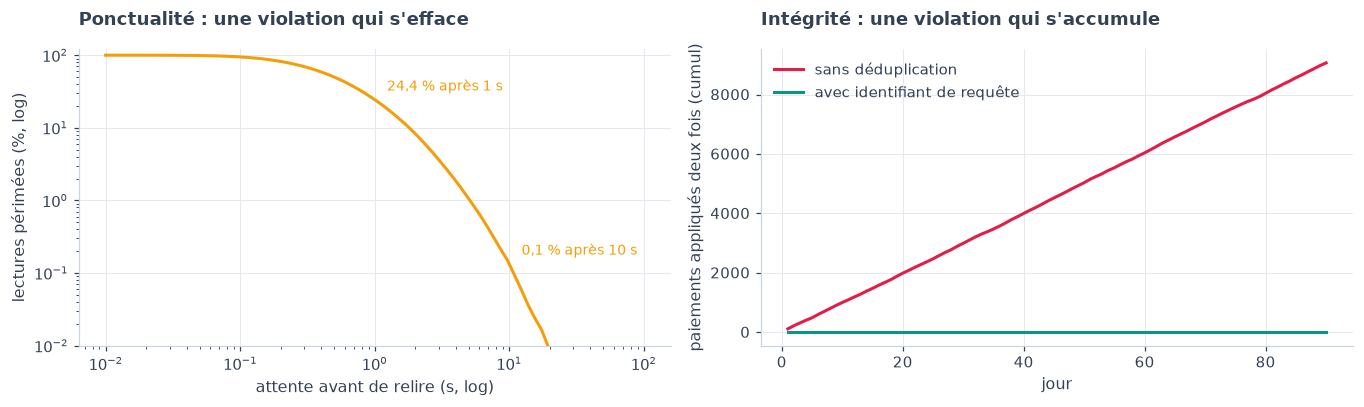

In [2]:
rng = np.random.default_rng(3)
lag = rng.lognormal(np.log(0.5), 1.0, 200_000)                  # délai de traitement (s)
waits = np.logspace(-2, 2, 80)
stale = [(lag > w).mean() for w in waits]
days = np.arange(1, 91)
per_day = 50_000
redeliv = 0.002                                                  # 0,2 % des messages relivrés après une panne
dup_naive = np.cumsum(rng.binomial(per_day, redeliv, days.size))  # appliqués deux fois sans déduplication
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.plot(waits, np.array(stale) * 100, color=AMBER)
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_ylim(0.01, 120)
ax1.set_xlabel("attente avant de relire (s, log)"); ax1.set_ylabel("lectures périmées (%, log)")
ax1.set_title("Ponctualité : une violation qui s'efface")
for w in (1, 10):
    v = (lag > w).mean() * 100
    ax1.annotate(f"{v:.1f} % après {w} s".replace(".", ","), (w, v), (8, 6), textcoords="offset points", fontsize=9, color=AMBER)
ax2.plot(days, dup_naive, color=ROSE, label="sans déduplication")
ax2.plot(days, np.zeros_like(days), color=TEAL, label="avec identifiant de requête")
ax2.set_xlabel("jour"); ax2.set_ylabel("paiements appliqués deux fois (cumul)")
ax2.set_title("Intégrité : une violation qui s'accumule"); ax2.legend()
plt.tight_layout(); plt.show()

La probabilité de lire un état périmé chute rapidement avec l'attente : une relecture
une seconde plus tard voit le paiement dans les trois quarts des cas, dix secondes plus
tard dans presque tous. À l'inverse, des relivraisons non dédupliquées s'**accumulent**
indéfiniment : environ cent paiements doublés par jour, soit près de 9 000 au bout de
trois mois, qu'aucune attente ne corrigera.

**Les flux découplent ponctualité et intégrité.** Les transactions ACID offrent les deux
à la fois (linéarisabilité et validation atomique), si bien que la distinction importe
peu tant qu'on raisonne en transactions. Les systèmes de flux d'événements, eux, n'offrent
**aucune** garantie de ponctualité (sauf à attendre explicitement un message), mais
l'**intégrité est au cœur** de leur conception : l'exactement-une-fois sert précisément à
la préserver. Le cours 4 l'a obtenue sans transaction distribuée par quatre mécanismes :

1. représenter le contenu de l'écriture par **un seul message**, facile à écrire
   atomiquement (ce qui s'accorde très bien avec l'event sourcing) ;
2. dériver toutes les autres mises à jour de ce message par des **fonctions déterministes**
   (à la manière de procédures stockées) ;
3. propager un **identifiant de requête** généré par le client à travers toutes les
   étapes, pour dédupliquer de bout en bout ;
4. garder les messages **immuables** et permettre de retraiter les données dérivées, pour
   se remettre des bogues.

> **À retenir.** « Cohérence » recouvre la ponctualité (voir un état à jour : violation
> temporaire) et l'intégrité (absence de corruption : violation permanente). L'intégrité
> est presque toujours la plus importante ; les systèmes de flux la garantissent sans
> transaction distribuée et renoncent à la ponctualité, qu'on peut rétablir en attendant.

## 2. Des contraintes interprétées souplement (section *Loosely interpreted constraints*)

Faire respecter une contrainte d'unicité classique exige un consensus (cours 4) : le
traitement de flux ne contourne pas cette limite. Mais beaucoup d'applications réelles
**autorisent**, pour des raisons métier, la violation de ce qu'on croirait être des
contraintes strictes :

- si les clients commandent plus d'articles qu'il n'y en a en entrepôt, on recommande,
  on s'excuse du retard, on offre une remise ; c'est ce qu'on ferait de toute façon si un
  chariot élévateur écrasait une palette. Le processus d'**excuse** existe déjà ;
- les compagnies aériennes et les hôtels **surréservent** volontairement, en comptant sur
  les absences, et ont des procédures de compensation (remboursement, surclassement,
  chambre dans l'hôtel voisin) ; elles en ont besoin de toute façon pour les vols annulés
  par la météo ou une grève ;
- une banque autorise un découvert, facture des frais et borne son risque en limitant les
  retraits quotidiens ;
- entre organisations, des incohérences apparaissent forcément, et des mécanismes de
  correction existent (le règlement des paiements interbancaires, chapitre 10).

Une modification qui corrige une erreur après coup s'appelle une **transaction de
compensation**. Le coût d'une excuse est une décision métier. Quantifions-le sur la
surréservation : un vol de 180 places, chaque passager se présente avec probabilité
0,92, un billet rapporte 150 EUR, un passager refoulé coûte une indemnité $c$
(`dfl.overbooking_profit`, loi binomiale).

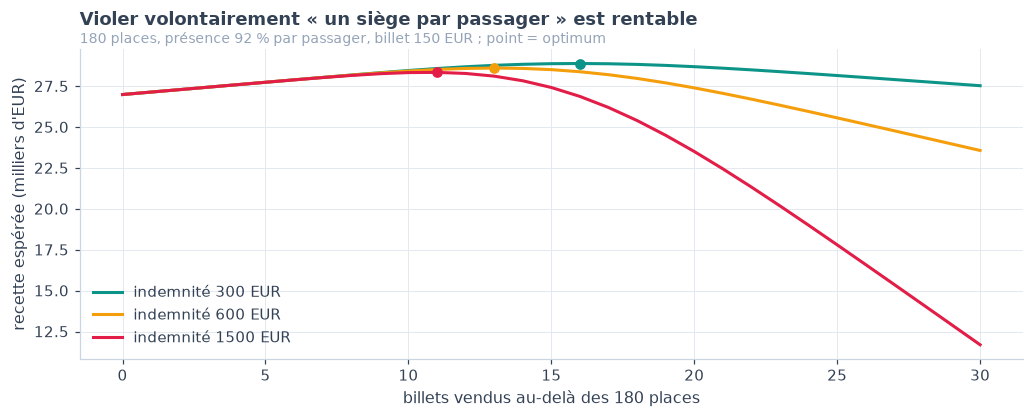

,indemnité (EUR),billets en trop optimaux,gain vs sans surréservation (EUR),P(au moins un refoulé)
0,300,16,1896.8157,0.4959
1,600,13,1619.6986,0.2219
2,1500,11,1354.3225,0.0960


In [3]:
cap, show, price = 180, 0.92, 150.0
fig, ax = plt.subplots(figsize=(9.5, 3.9))
rows = []
for c, col in [(300, TEAL), (600, AMBER), (1500, ROSE)]:
    best, prof = dfl.best_overbooking(cap, show, price, c, max_extra=30)
    ax.plot(range(31), np.array(prof) / 1000, color=col, label=f"indemnité {c} EUR")
    ax.scatter([best], [prof[best] / 1000], color=col, zorder=3)
    p_bump = sum(math.comb(cap + best, j) * show ** j * (1 - show) ** (cap + best - j) for j in range(cap + 1, cap + best + 1))
    rows.append({"indemnité (EUR)": c, "billets en trop optimaux": best, "gain vs sans surréservation (EUR)": prof[best] - prof[0],
                 "P(au moins un refoulé)": p_bump})
ax.set_xlabel("billets vendus au-delà des 180 places"); ax.set_ylabel("recette espérée (milliers d'EUR)")
ax.set_title("Violer volontairement « un siège par passager » est rentable")
subtitle(ax, "180 places, présence 92 % par passager, billet 150 EUR ; point = optimum")
ax.legend(); plt.tight_layout(); plt.show()
pd.DataFrame(rows)

Même avec une indemnité dix fois supérieure au prix du billet, vendre quelques billets
de trop reste rentable ; la compagnie accepte délibérément qu'un vol sur dix (avec une
indemnité de 1 500 EUR) à un vol sur deux (300 EUR) refoule quelqu'un, et a prévu
l'excuse. Si le coût de l'excuse est acceptable, vérifier
toutes les contraintes **avant** d'écrire est inutilement restrictif : on peut écrire de
façon optimiste et vérifier **après coup**, en gardant une validation préalable pour les
actions coûteuses à défaire (un billet de banque sorti du distributeur ne se récupère pas
facilement). Ces applications exigent l'**intégrité** (ne pas perdre une réservation, ne
pas faire disparaître d'argent), pas la **ponctualité** de la vérification de la
contrainte. C'est l'esprit de la résolution de conflits du chapitre 5.

> **À retenir.** Beaucoup de contraintes « strictes » sont en réalité souples : le métier
> sait déjà s'excuser et compenser. On peut alors écrire d'abord, vérifier ensuite, et
> réserver la vérification synchrone aux actions irréversibles.

## 3. Des systèmes qui évitent la coordination (section *Coordination-avoiding data systems*)

Deux observations, mises bout à bout :

- les systèmes de flux maintiennent l'**intégrité** des données dérivées sans validation
  atomique, sans linéarisabilité, sans coordination synchrone entre partitions ;
- les contraintes strictes exigent ponctualité et coordination, mais beaucoup
  d'applications se contentent de contraintes **souples**, violées temporairement puis
  réparées, tant que l'intégrité est préservée.

Donc beaucoup d'applications peuvent se passer de coordination tout en gardant des
garanties d'intégrité fortes : de tels systèmes sont plus performants et plus tolérants
aux pannes. Par exemple, plusieurs centres de données en configuration multi-leader,
répliqués de façon asynchrone, chacun capable de fonctionner seul. La coordination
synchrone reste disponible là où elle est nécessaire (avant une action irréversible),
sans que toute l'application en paie le prix. Le livre conclut par une image : la
coordination **réduit les excuses pour incohérence**, mais **augmente les excuses pour
indisponibilité** ; on ne peut pas descendre à zéro excuse, seulement chercher le meilleur
compromis.

Rendons cette image concrète (`dfl.inventory_regions`) : un stock de 1 000 articles vendu
depuis trois régions, chacune voyant les ventes des autres avec 5 s de retard. Tant que
son estimation du stock restant dépasse un **seuil** $S$, une région vend sans
coordination ; en dessous, elle consulte un coordinateur, injoignable pendant les coupures
réseau (une région est coupée 15 % du temps). On compte les ventes au-delà du stock
(excuses pour incohérence) et les refus pendant une coupure alors qu'il restait du stock
(excuses pour indisponibilité).

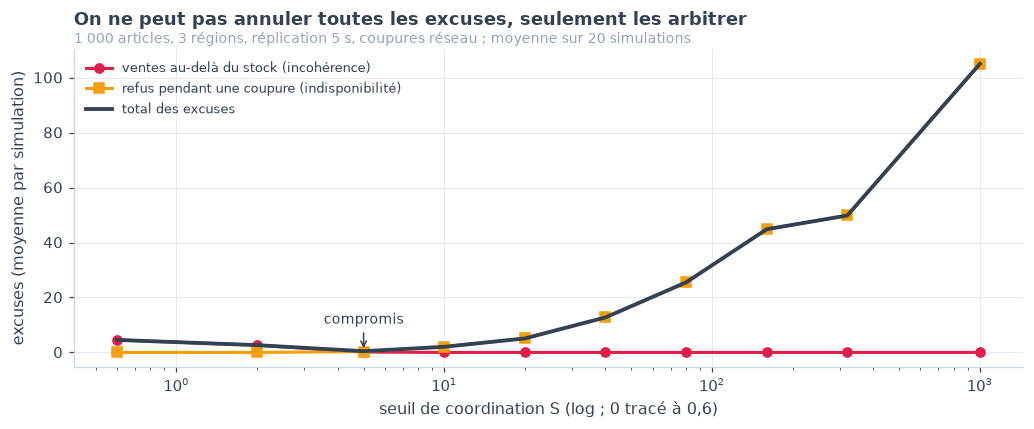

,seuil S,oversold,refused_outage,coordinations,excuses (total)
0,0,4.6,0.0,192.9,4.6
1,2,2.6,0.0,194.8,2.6
2,5,0.2,0.3,198.6,0.4
3,10,0.0,2.0,203.4,2.0
4,20,0.0,5.1,213.0,5.1
5,40,0.0,12.8,233.1,12.8
6,80,0.0,25.5,273.5,25.5
7,160,0.0,44.8,353.6,44.8
8,320,0.0,49.8,513.4,49.8
9,1000,0.0,105.0,1197.4,105.0


In [4]:
cuts = {0: [(200, 260), (700, 760)], 1: [(400, 470)], 2: [(780, 850)]}
seuils = [0, 2, 5, 10, 20, 40, 80, 160, 320, 1000]
rows = []
for S in seuils:
    acc = {"oversold": [], "refused_outage": [], "coordinations": []}
    for seed in range(20):
        r = dfl.inventory_regions(S, stock=1000, n_regions=3, rate=0.4, horizon=1000, repl_delay=5.0,
                                  partitions=cuts, seed=seed)
        for k in acc:
            acc[k].append(r[k])
    rows.append({"seuil S": S, **{k: np.mean(v) for k, v in acc.items()}})
R = pd.DataFrame(rows)
R["excuses (total)"] = R["oversold"] + R["refused_outage"]
fig, ax = plt.subplots(figsize=(9.5, 4))
xs = [max(s, 0.6) for s in R["seuil S"]]
ax.plot(xs, R["oversold"], "o-", color=ROSE, label="ventes au-delà du stock (incohérence)")
ax.plot(xs, R["refused_outage"], "s-", color=AMBER, label="refus pendant une coupure (indisponibilité)")
ax.plot(xs, R["excuses (total)"], color=SLATE, lw=2.5, label="total des excuses")
i = R["excuses (total)"].idxmin()
ax.annotate("compromis", (xs[i], R["excuses (total)"][i]), (0, 18), textcoords="offset points", ha="center",
            color=SLATE, fontsize=9, arrowprops=dict(arrowstyle="->", color=SLATE))
ax.set_xscale("log"); ax.set_xlabel("seuil de coordination S (log ; 0 tracé à 0,6)")
ax.set_ylabel("excuses (moyenne par simulation)")
ax.set_title("On ne peut pas annuler toutes les excuses, seulement les arbitrer")
subtitle(ax, "1 000 articles, 3 régions, réplication 5 s, coupures réseau ; moyenne sur 20 simulations")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()
R.round(1)

Sans coordination ($S = 0$), les dernières unités sont vendues plusieurs fois (chaque
région croit qu'il en reste), d'où quelques ventes à rembourser. Avec un seuil de
quelques articles (5 ici), de l'ordre du nombre de ventes possibles pendant le délai de
réplication (3 régions × 0,4 vente/s × 5 s ≈ 6), la survente disparaît presque, et la
coordination ne concerne que la toute fin du stock : presque aucun refus. Au-delà, chaque vente supplémentaire coordonnée s'expose aux
coupures, et les refus augmentent jusqu'à toucher toutes les ventes faites pendant les
coupures. Le total des excuses a un minimum : le **compromis** du livre, avec ni trop
d'incohérences ni trop d'indisponibilité. Dans ce cadre, des transactions sérialisables
restent utiles, mais à **petite échelle** (au sein d'un partition, pour l'état dérivé), et les
transactions distribuées hétérogènes (XA) ne sont plus nécessaires.

> **À retenir.** Des systèmes qui maintiennent l'intégrité sans coordination, et
> n'introduisent de coordination synchrone que là où une violation serait irréparable,
> obtiennent de meilleures performances et une meilleure tolérance aux pannes. Coordonner
> réduit les incohérences mais augmente les indisponibilités : on choisit un compromis.

## 4. Faire confiance, mais vérifier (sections *Trust, but Verify*, *Maintaining integrity in the face of software bugs* et *Don't just blindly trust what they promise*)

Toute la discussion repose sur un **modèle de système** (chapitre 8) : on
suppose que certaines choses peuvent mal tourner (plantages, pertes de courant, délais et
pertes réseau) et que d'autres non (les données écrites après `fsync` ne sont pas
perdues, la mémoire n'est pas corrompue, l'instruction de multiplication du processeur
donne le bon résultat). Ces hypothèses binaires sont commodes, mais la réalité est
**probabiliste** : la question est de savoir si les violations sont assez fréquentes pour
nous arriver. Or à grande échelle, même l'improbable arrive. Ordre de grandeur : un taux
d'erreurs non détectées de $10^{-15}$ par bit lu semble négligeable, mais un système qui
lit un pétaoctet par jour lit $8 \cdot 10^{15}$ bits.

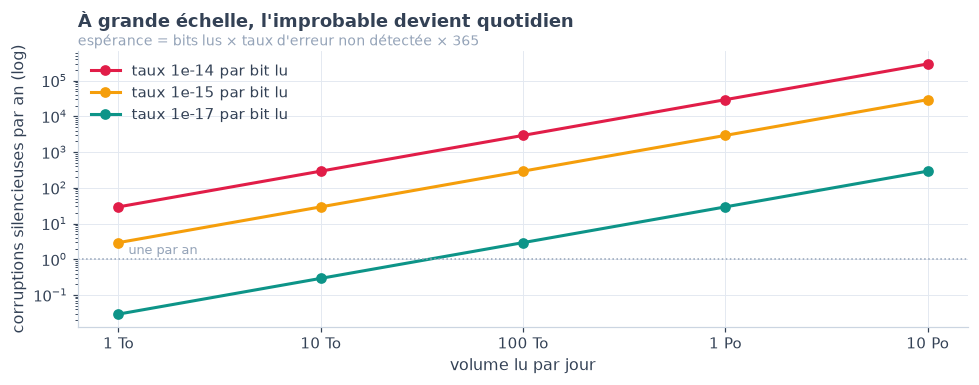

In [5]:
lu_par_jour = np.array([1e12, 1e13, 1e14, 1e15, 1e16]) * 8      # bits lus par jour (1 To à 10 Po)
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ["1 To", "10 To", "100 To", "1 Po", "10 Po"]
for ber, col in [(1e-14, ROSE), (1e-15, AMBER), (1e-17, TEAL)]:
    ax.plot(labels, lu_par_jour * ber * 365, "o-", color=col, label=f"taux {ber:.0e} par bit lu")
ax.set_yscale("log"); ax.axhline(1, color=GRAY, ls=":", lw=1)
ax.text(0.05, 1.4, "une par an", fontsize=8.5, color=GRAY)
ax.set_xlabel("volume lu par jour"); ax.set_ylabel("corruptions silencieuses par an (log)")
ax.set_title("À grande échelle, l'improbable devient quotidien")
subtitle(ax, "espérance = bits lus × taux d'erreur non détectée × 365")
ax.legend(); plt.tight_layout(); plt.show()

À un pétaoctet lu par jour, un taux de $10^{-15}$ donne environ **huit corruptions
silencieuses par jour**, et même un taux cent fois meilleur en laisse une trentaine par
an. Les chapitres précédents ont montré que les données se corrompent en mémoire,
sur disque et sur le réseau.

**Les bogues logiciels.** S'y ajoutent les bogues, que les sommes de contrôle de bas
niveau ne voient pas. Même des bases éprouvées en ont eu : certaines versions de MySQL
n'ont pas su maintenir correctement une contrainte d'unicité, et le niveau sérialisable
de PostgreSQL a présenté des anomalies de write skew. Le code applicatif, beaucoup moins
revu et testé, a bien plus de bogues, et beaucoup d'applications n'utilisent même pas
correctement les contraintes d'intégrité (clés étrangères, unicité) qu'offrent les bases.
La cohérence au sens d'ACID suppose que chaque transaction fait passer la base d'un état
cohérent à un autre : cela n'a de sens que si la transaction est **sans bogue**.

**Ne pas croire aveuglément.** Puisque la corruption finira par arriver, il faut au moins
pouvoir la **détecter** pour la réparer et en chercher la cause : c'est l'**audit**. Les
systèmes de stockage matures (HDFS, Amazon S3) ne font pas une confiance totale aux
disques : des processus d'arrière-plan relisent continuellement les fichiers, les
comparent aux autres répliques et les déplacent, pour limiter le risque de corruption
silencieuse. Si vous voulez être sûr que vos données sont là, **relisez-les** ; de même,
essayez de **restaurer** vos sauvegardes de temps en temps, sinon vous découvrirez
qu'elles sont inutilisables le jour où vous en aurez besoin. Quantifions l'effet de la
vérification périodique (`dfl.scrub_loss_probability`) : chaque copie d'un bloc se
corrompt silencieusement au taux de 2 % par an ; une vérification tous les $\tau$ répare
les copies corrompues à partir d'une copie saine, et le bloc n'est perdu que si toutes
ses copies se corrompent entre deux vérifications.

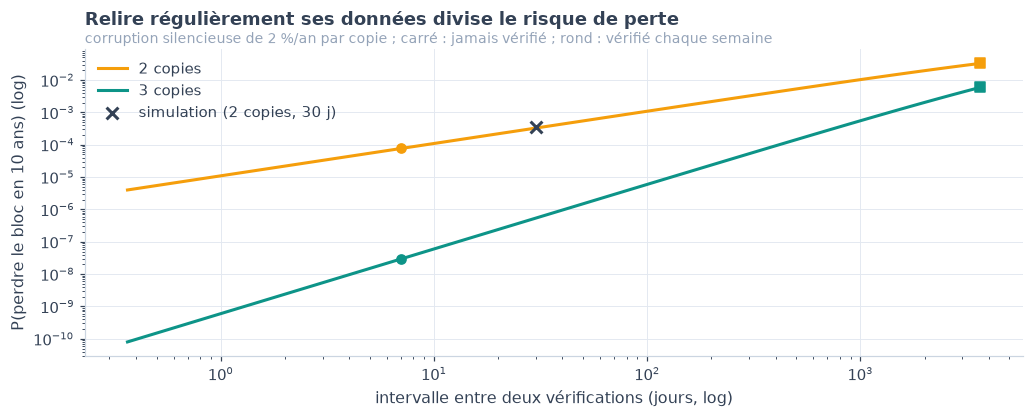

2 copies : jamais vérifié 3.3e-02, chaque semaine 7.7e-05
3 copies : jamais vérifié 6.0e-03, chaque semaine 2.9e-08
2 copies, 30 jours : formule 3.28e-04, simulation 3.45e-04


In [6]:
rate, H = 0.02, 10.0                                            # par an, horizon 10 ans
taus = np.logspace(-3, 1, 60)                                   # de ~9 h à 10 ans
fig, ax = plt.subplots(figsize=(9.5, 3.9))
for r_, col in [(2, AMBER), (3, TEAL)]:
    ax.plot(taus * 365, [dfl.scrub_loss_probability(r_, rate, t, H) for t in taus], color=col, label=f"{r_} copies")
    for t, mk in [(7 / 365, "o"), (H, "s")]:
        ax.scatter([t * 365], [dfl.scrub_loss_probability(r_, rate, t, H)], color=col, marker=mk, zorder=3)
sim = dfl.simulate_scrubbing(200_000, 2, rate, 30 / 365, H, seed=1) / 200_000
ax.scatter([30], [sim], color=SLATE, marker="x", s=60, zorder=4, label="simulation (2 copies, 30 j)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("intervalle entre deux vérifications (jours, log)"); ax.set_ylabel("P(perdre le bloc en 10 ans) (log)")
ax.set_title("Relire régulièrement ses données divise le risque de perte")
subtitle(ax, "corruption silencieuse de 2 %/an par copie ; carré : jamais vérifié ; rond : vérifié chaque semaine")
ax.legend(); plt.tight_layout(); plt.show()
for r_ in (2, 3):
    print(f"{r_} copies : jamais vérifié {dfl.scrub_loss_probability(r_, rate, H, H):.1e}, "
          f"chaque semaine {dfl.scrub_loss_probability(r_, rate, 7 / 365, H):.1e}")
print(f"2 copies, 30 jours : formule {dfl.scrub_loss_probability(2, rate, 30 / 365, H):.2e}, simulation {sim:.2e}")

Sans vérification, deux copies ne protègent guère : en dix ans, chacune a 18 % de chances
de s'être corrompue, et les deux ensemble 3 %. Vérifier chaque semaine ramène ce risque
sous $10^{-4}$, plus de quatre cents fois moins : on répare la première copie corrompue bien avant que la seconde ne
le soit. La pente de la courbe vaut le nombre de copies moins un : avec trois copies, le
gain est encore plus spectaculaire. Le point simulé confirme la formule.

**Une culture de la vérification** (*A culture of verification*). HDFS et S3 supposent
encore que les disques fonctionnent correctement **la plupart du temps**, ce qui est
raisonnable, et différent de supposer qu'ils fonctionnent **toujours**. Peu de systèmes
ont aujourd'hui cette approche « faire confiance, mais vérifier » qui consiste à s'auditer
en continu ; beaucoup tiennent leurs garanties pour absolues. Le livre craint que la
culture ACID ait habitué les développeurs à se reposer aveuglément sur la technologie (une
base transactionnelle « ne peut pas » être incohérente), et que des technologies aux
garanties plus faibles aient été adoptées sans mécanismes d'audit. Il espère voir
davantage de systèmes qui vérifient eux-mêmes leur intégrité en continu.

> **À retenir.** Les modèles de système sont binaires, la réalité est probabiliste : à
> grande échelle, corruptions et bogues arrivent. Il faut **auditer** : relire ses données,
> les comparer aux répliques, tester ses restaurations. La vérification périodique divise le
> risque de perte par des ordres de grandeur.

## 5. Concevoir pour l'auditabilité (sections *Designing for auditability* et *The end-to-end argument again*)

Quand une transaction modifie plusieurs objets, la **raison** de ces modifications est
difficile à retrouver après coup : même avec les journaux de transactions, les
insertions, mises à jour et suppressions dans diverses tables ne disent pas **pourquoi**
elles ont eu lieu ; l'invocation de la logique applicative qui les a décidées est
éphémère. Un système à base d'événements est plus **auditable** : avec l'event sourcing,
l'entrée de l'utilisateur est un événement immuable unique, et toutes les mises à jour
d'état en dérivent de façon **déterministe et rejouable**. Expliciter le flux de données
rend la **provenance** claire, ce qui rend la vérification d'intégrité réaliste :

- pour le journal d'événements, des **hachages** permettent de vérifier que le stockage
  n'a pas été corrompu ;
- pour l'état dérivé, on peut **rejouer** les traitements qui l'ont produit et comparer, ou
  même faire tourner une **dérivation redondante** en parallèle ;
- un flux déterministe permet aussi de **déboguer en remontant le temps** : reproduire
  exactement les circonstances qui ont mené à un événement inattendu.

Démonstration : un journal d'événements de compte, **chaîné par hachage**
(`dfl.HashChainLog` : chaque entrée contient le hachage de la précédente), dont on dérive
les soldes. On falsifie une entrée ancienne, puis on introduit un bogue dans une
dérivation, et on regarde ce que chaque vérification détecte.

In [7]:
rng = random.Random(5)
journal = dfl.HashChainLog()
for i in range(2000):
    journal.append(f"{i};c{rng.randrange(50)};{rng.choice([-1, 1]) * rng.randint(1, 100)}")

def deriver(entries, bogue=False):
    soldes = {}
    for e in entries:
        i, c, m = e["payload"].split(";")
        m = int(m)
        if bogue and int(i) >= 1500 and m < 0:      # une nouvelle version oublie les débits de plus de 90
            m = 0 if m < -90 else m
        soldes[c] = soldes.get(c, 0) + m
    return soldes

def empreinte(soldes):
    return hashlib.sha256(repr(sorted(soldes.items())).encode()).hexdigest()[:12]

reference = deriver(journal.entries)
tete = journal.head()
rows = [("journal intact", journal.verify(), empreinte(deriver(journal.entries)) == empreinte(reference))]
falsifie = [dict(e) for e in journal.entries]
falsifie[700]["payload"] = falsifie[700]["payload"].rsplit(";", 1)[0] + ";+5000"
copie = dfl.HashChainLog(); copie.entries = falsifie
rows.append(("entrée 700 falsifiée", copie.verify(), None))
v_bug = deriver(journal.entries, bogue=True)
rows.append(("dérivation boguée (nouvelle version)", journal.verify(), empreinte(v_bug) == empreinte(reference)))
rows = [(a, "aucune" if b is None else b, "sans objet" if c is None else ("oui" if c else "non")) for a, b, c in rows]
pd.DataFrame(rows, columns=["scénario", "première entrée incohérente de la chaîne", "dérivation redondante concordante"])

,scénario,première entrée incohérente de la chaîne,dérivation redondante concordante
0,journal intact,aucune,oui
1,entrée 700 falsifiée,700,sans objet
2,dérivation boguée (nouvelle version),aucune,non


La chaîne de hachage localise la falsification **à l'entrée près** (l'entrée 700), car
modifier une entrée change son hachage, qui ne correspond plus à celui que mémorise
l'entrée suivante. Pour être inviolable, la tête de chaîne doit être publiée ou signée
ailleurs (un module matériel de sécurité, par exemple), sinon un attaquant pourrait
recalculer toute la chaîne. Le bogue de dérivation, lui, laisse le journal intact : seule
la **comparaison avec une dérivation redondante** (ici l'ancienne version du code) le
révèle. Et comme tout est déterministe, on peut rejouer le journal jusqu'à n'importe quel
offset pour retrouver **à partir de quand** les deux dérivations divergent :

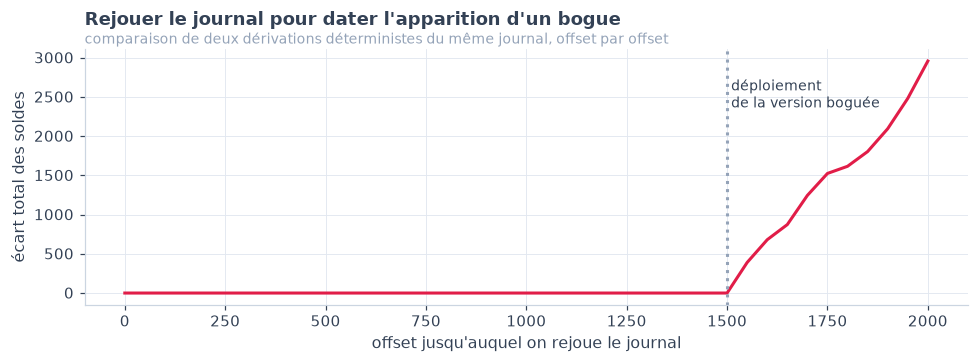

In [8]:
offsets = np.arange(0, 2001, 50)
ecart = [sum(abs(deriver(journal.entries[:k])[c] - deriver(journal.entries[:k], bogue=True)[c])
             for c in deriver(journal.entries[:k])) for k in offsets]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(offsets, ecart, color=ROSE)
ax.axvline(1500, color=GRAY, ls=":"); ax.text(1510, max(ecart) * 0.8, "déploiement\nde la version boguée", fontsize=9, color=SLATE)
ax.set_xlabel("offset jusqu'auquel on rejoue le journal"); ax.set_ylabel("écart total des soldes")
ax.set_title("Rejouer le journal pour dater l'apparition d'un bogue")
subtitle(ax, "comparaison de deux dérivations déterministes du même journal, offset par offset")
plt.tight_layout(); plt.show()

Les deux dérivations coïncident jusqu'à l'offset 1 500, puis divergent : on date le bogue
sans hésitation. C'est l'**argument de bout en bout, à nouveau** : si l'on ne peut pas
faire entièrement confiance à chaque composant, il faut vérifier périodiquement
l'intégrité des données, et le faire **de bout en bout**. Plus une vérification englobe de
systèmes, moins la corruption a de chances de passer inaperçue ; vérifier tout un pipeline
de dérivation inclut implicitement les disques, réseaux, services et algorithmes sur le
chemin. Comme les tests automatisés, l'audit continu donne confiance, et la confiance
permet d'aller **plus vite** : on n'a plus peur de changer le système.

> **À retenir.** Un système à base d'événements immuables et de dérivations déterministes
> est auditable : hachages pour le journal, rejeu et dérivations redondantes pour l'état
> dérivé, débogage par remontée dans le temps. La vérification la plus utile est celle de
> bout en bout.

## 6. Outils pour des systèmes auditables : chaînes de hachage et arbres de Merkle (section *Tools for auditable data systems*)

Peu de systèmes font de l'auditabilité une priorité. Certaines applications tiennent une
table d'audit séparée, mais garantir l'intégrité de cette table et de la base reste
difficile. Signer périodiquement le journal de transactions avec un module matériel de
sécurité le rend inviolable, sans garantir que les **bonnes** transactions y sont entrées.

Les **chaînes de blocs** (Bitcoin, Ethereum) sont des journaux partagés en ajout seul avec
des vérifications cryptographiques : les transactions sont des événements, les contrats
intelligents des processeurs de flux, et le consensus garantit que tous les nœuds
s'accordent sur la même séquence. Contrairement aux protocoles du chapitre
9, ils tolèrent les **fautes byzantines** (des participants aux données
corrompues), parce que les répliques vérifient continuellement l'intégrité les unes des
autres. Pour la plupart des applications, leur surcoût est trop élevé ; mais certains de
leurs outils cryptographiques sont utiles à moindre échelle. Les **arbres de Merkle** sont
des arbres de hachages qui permettent de **prouver** efficacement qu'un enregistrement
appartient à un jeu de données. La **transparence des certificats** les utilise, avec des
journaux en ajout seul vérifiés cryptographiquement, pour contrôler la validité des
certificats TLS, sans protocole de consensus (un seul leader par journal).

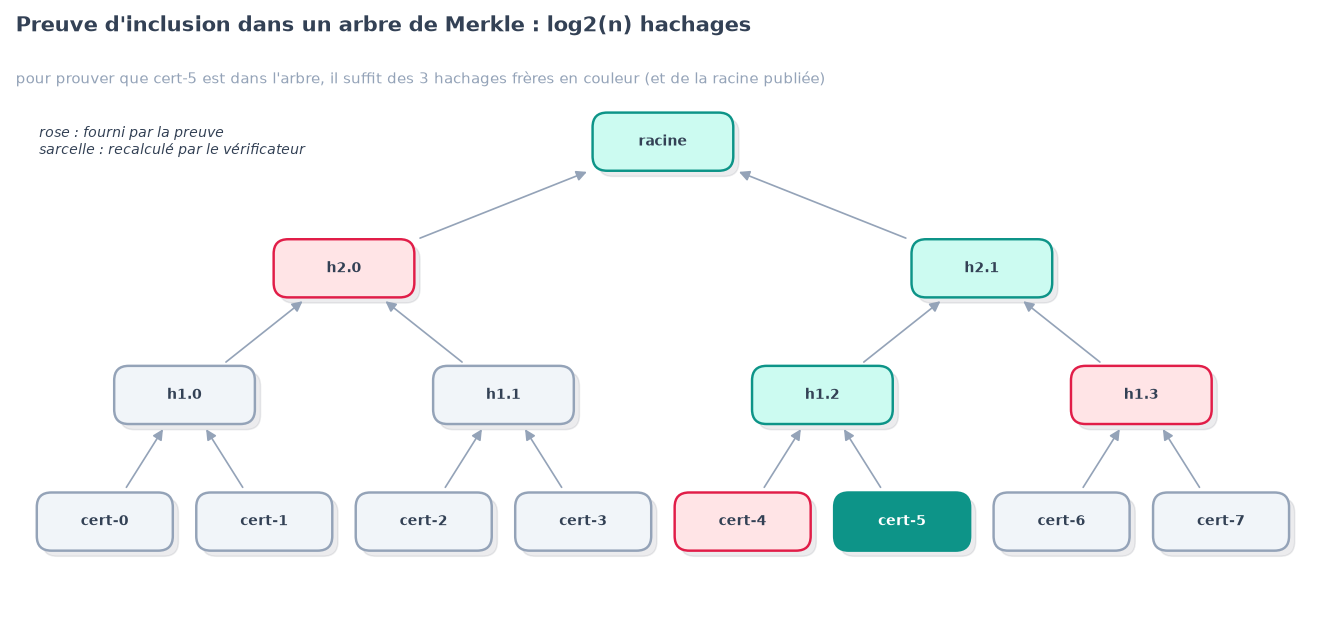

preuve : [('gauche', 'ca5078fcf2'), ('droite', 'a05db83b3b'), ('gauche', 'c9bbc4fa8b')]
vérification : True ; avec un faux certificat : False


In [9]:
leaves = [f"cert-{i}" for i in range(8)]
t = dfl.MerkleTree(leaves)
proof = t.proof(5)
d = Diagram(14, 5.4, title="Preuve d'inclusion dans un arbre de Merkle : log2(n) hachages",
            subtitle="pour prouver que cert-5 est dans l'arbre, il suffit des 3 hachages frères en couleur (et de la racine publiée)")
xs = [1.0 + i * 1.7 for i in range(8)]
levels = {0: [(x, 0.9) for x in xs]}
for lvl in range(1, 4):
    prev = levels[lvl - 1]
    levels[lvl] = [((prev[2 * i][0] + prev[2 * i + 1][0]) / 2, 0.9 + lvl * 1.35) for i in range(len(prev) // 2)]
path = {(0, 5), (1, 2), (2, 1), (3, 0)}          # chemin de cert-5 vers la racine
sib = {(0, 4), (1, 3), (2, 0)}                   # hachages frères fournis par la preuve
for lvl, nodes in levels.items():
    for i, (x, y) in enumerate(nodes):
        name = f"n{lvl}_{i}"
        txt = leaves[i] if lvl == 0 else ("racine" if lvl == 3 else f"h{lvl}.{i}")
        col = ROSE if (lvl, i) in sib else (TEAL if (lvl, i) in path else GRAY)
        d.box(name, x, y, txt, color=col, w=1.45 if lvl == 0 else 1.5, h=0.62, fontsize=9,
              filled=(lvl, i) in path and lvl == 0)
        if lvl > 0:
            d.arrow(f"n{lvl - 1}_{2 * i}", name, color=GRAY, lw=1.1)
            d.arrow(f"n{lvl - 1}_{2 * i + 1}", name, color=GRAY, lw=1.1)
d.note(0.3, 4.95, "rose : fourni par la preuve\nsarcelle : recalculé par le vérificateur", color=SLATE, ha="left")
d.show()
print("preuve :", [(cote, h.hex()[:10]) for cote, h in proof])
print("vérification :", dfl.MerkleTree.verify_proof("cert-5", proof, t.root()),
      "; avec un faux certificat :", dfl.MerkleTree.verify_proof("cert-5-faux", proof, t.root()))

Le vérificateur recalcule le hachage de la feuille, le combine avec les trois hachages
frères, et compare le résultat à la racine publiée : un faux certificat donne une autre
racine. La taille de la preuve croît comme $\log_2 n$ : prouver l'appartenance d'un
enregistrement à un journal d'un milliard d'entrées demande une trentaine de hachages.
Les arbres de Merkle servent aussi à **comparer deux répliques** (l'anti-entropie du
chapitre 5) : on compare les racines, et l'on ne descend que dans les
sous-arbres qui diffèrent.

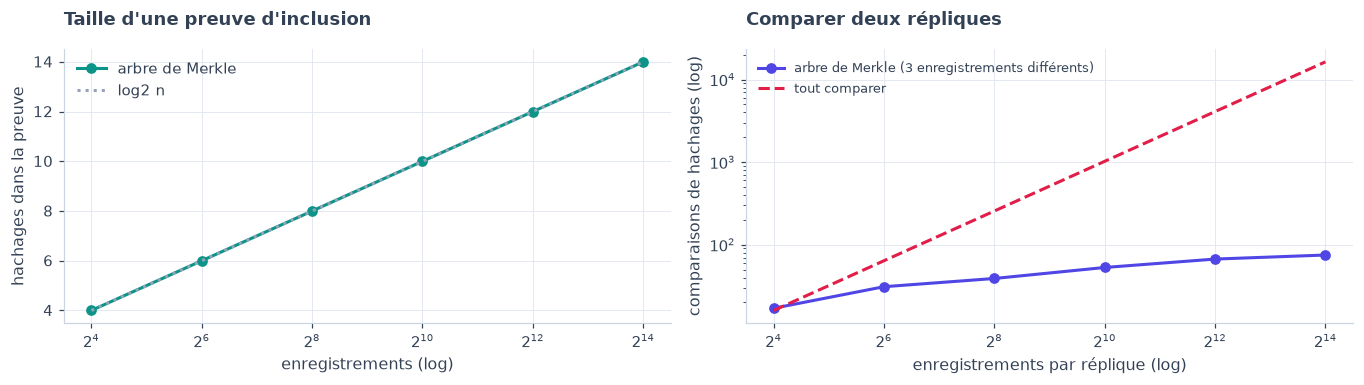

,enregistrements,hachages par preuve,comparaisons (3 différences)
0,16,4,17
1,64,6,31
2,256,8,39
3,1024,10,53
4,4096,12,67
5,16384,14,75


In [10]:
ns = [2 ** k for k in range(4, 21, 2)]
proof_len = [len(dfl.MerkleTree([str(i) for i in range(n)]).proof(n // 3)) for n in ns[:6]]
comps = []
rng = random.Random(0)
for n in ns[:6]:
    a = [str(i) for i in range(n)]
    b = list(a)
    for j in rng.sample(range(n), 3):
        b[j] = "corrompu"
    diff, c = dfl.MerkleTree(a).diff(dfl.MerkleTree(b))
    comps.append(c)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6))
ax1.plot(ns[:6], proof_len, "o-", color=TEAL, label="arbre de Merkle")
ax1.plot(ns[:6], np.log2(ns[:6]), color=GRAY, ls=":", label="log2 n")
ax1.set_xscale("log", base=2); ax1.set_xlabel("enregistrements (log)"); ax1.set_ylabel("hachages dans la preuve")
ax1.set_title("Taille d'une preuve d'inclusion"); ax1.legend()
ax2.plot(ns[:6], comps, "o-", color=INDIGO, label="arbre de Merkle (3 enregistrements différents)")
ax2.plot(ns[:6], ns[:6], color=ROSE, ls="--", label="tout comparer")
ax2.set_xscale("log", base=2); ax2.set_yscale("log")
ax2.set_xlabel("enregistrements par réplique (log)"); ax2.set_ylabel("comparaisons de hachages (log)")
ax2.set_title("Comparer deux répliques"); ax2.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
pd.DataFrame({"enregistrements": ns[:6], "hachages par preuve": proof_len, "comparaisons (3 différences)": comps})

La preuve suit exactement $\log_2 n$ ; la comparaison de deux répliques qui diffèrent sur
trois enregistrements ne coûte que quelques dizaines de comparaisons de hachages, au lieu
d'une par enregistrement. Le livre pense que ces algorithmes de vérification (ceux de la
transparence des certificats et des registres distribués) pourraient se diffuser dans les
systèmes de données, à condition de les rendre aussi scalables que des systèmes sans
audit cryptographique et d'en réduire le surcoût.

> **À retenir.** Chaînes de hachage et arbres de Merkle rendent la falsification
> détectable et l'appartenance prouvable en $O(\log n)$ ; les arbres de Merkle comparent
> aussi des répliques à moindre coût. Les chaînes de blocs y ajoutent un consensus
> byzantin, souvent trop cher ; leurs outils cryptographiques, eux, sont réutilisables.

## Synthèse

- « Cohérence » mêle **ponctualité** (violation temporaire) et **intégrité** (violation
  permanente) ; les systèmes de flux sacrifient la première et garantissent la seconde par
  un message atomique, des dérivations déterministes, des identifiants de bout en bout et
  des données immuables.
- Beaucoup de contraintes sont **souples** : on écrit d'abord, on vérifie ensuite, on
  compense ; la coordination est réservée aux actions irréversibles, et le nombre d'excuses
  se règle par un compromis entre incohérences et indisponibilités.
- **Faire confiance, mais vérifier** : à grande échelle, corruptions et bogues arrivent ;
  relire, comparer, rejouer et tester ses restaurations.
- Les systèmes à base d'événements sont **auditables** ; chaînes de hachage et arbres de
  Merkle rendent la vérification efficace.

**Bilan du chapitre.** Aucun outil ne sert tous les usages : on compose des systèmes
spécialisés en désignant un système de référence et en **dérivant** le reste par des flux
(cours 1) ; c'est **dégrouper la base** à l'échelle de l'organisation (cours 2), jusqu'à
l'écran de l'utilisateur (cours 3) ; la justesse s'obtient **de bout en bout**, par des
identifiants de requête et des contraintes vérifiées de façon asynchrone (cours 4 et 5),
en évitant la coordination autant que possible. La dernière section du chapitre, *Doing the Right Thing* (cours 6 et 7), prend du recul : à quoi servent ces systèmes, et quelles en sont les conséquences pour les personnes dont ils traitent les données ?